<a href="https://colab.research.google.com/github/KAji-SaputraRomadhon/PM-Turi4-clustering/blob/main/PM_Pertemuan9_Kurniawan_aji_saputra_R_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 9 — Clustering dengan K-Means
**Mata Kuliah:** Pembelajaran Mesin

**Nama / NIM:** Kurniawan Aji Saputra Romadhon (2488010027)

**Tujuan:** menyiapkan data tanpa label (scaling), menentukan K dengan Elbow, menerapkan K-Means, mengevaluasi dengan silhouette score, dan menafsirkan cluster sebagai segmen pelanggan.

## 0. Dataset segmentasi pelanggan (buatan)
Dataset sintetis 200 pelanggan dengan fitur `usia` (tahun), `pendapatan` (Rp/bulan), dan `skor_belanja` (1–100). **Kolom label tidak ada** — kita hanya memakai fitur untuk clustering.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)
def grup(n, usia, pendapatan, skor):
    return pd.DataFrame({'usia': rng.normal(*usia, n),
                         'pendapatan': rng.normal(*pendapatan, n),
                         'skor_belanja': rng.normal(*skor, n)})

df = pd.concat([
    grup(70, (24, 3.5), (5.5e6, 1.2e6), (78, 8)),    # muda, pendapatan rendah, belanja tinggi
    grup(60, (38, 5),   (16e6, 2.5e6),  (80, 8)),    # dewasa, pendapatan tinggi, belanja tinggi
    grup(70, (50, 6),   (6.5e6, 1.5e6), (25, 8)),    # paruh baya, pendapatan rendah, belanja rendah
], ignore_index=True)
df['usia'] = df['usia'].clip(18, 65).round().astype(int)
df['pendapatan'] = (df['pendapatan'].clip(2e6) / 1e5).round() * 1e5
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round().astype(int)

print(df.shape)
display(df.head())
display(df.describe().round(1))

(200, 3)


,usia,pendapatan,skor_belanja
0,25,4000000.0,81
1,20,4100000.0,70
2,27,4400000.0,61
3,27,6100000.0,80
4,18,5700000.0,71


,usia,pendapatan,skor_belanja
count,200.0,200.0,200.0
mean,37.3,9050000.0,59.4
std,11.7,5105362.2,27.6
min,18.0,2100000.0,6.0
25%,26.0,5275000.0,27.8
50%,37.0,6600000.0,72.0
75%,48.0,13575000.0,81.0
max,62.0,21200000.0,99.0


## Langkah 1 — Menyiapkan data & scaling (wajib)
K-Means berbasis jarak Euclidean. Skala `pendapatan` (jutaan) jauh lebih besar daripada `usia` (puluhan), sehingga tanpa scaling pendapatan akan mendominasi jarak. `StandardScaler` mengubah tiap fitur menjadi rata-rata 0 dan simpangan baku 1.

In [ ]:
X_scaled = StandardScaler().fit_transform(df)
print(pd.DataFrame(X_scaled, columns=df.columns).describe().loc[['mean', 'std']].round(2))

      usia  pendapatan  skor_belanja
mean   0.0         0.0           0.0
std    1.0         1.0           1.0


## Langkah 2 — Metode Elbow menentukan K

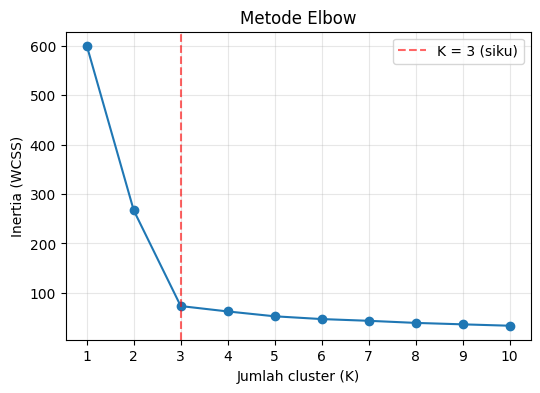

K= 1  inertia=   600.0
K= 2  inertia=   266.8
K= 3  inertia=    73.3
K= 4  inertia=    62.4
K= 5  inertia=    52.6
K= 6  inertia=    47.0
K= 7  inertia=    43.4
K= 8  inertia=    39.2
K= 9  inertia=    36.3
K=10  inertia=    33.5


In [ ]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(3, color='red', ls='--', alpha=.6, label='K = 3 (siku)')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia (WCSS)')
plt.title('Metode Elbow'); plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=.3)
plt.show()

for k, i in zip(range(1, 11), inertias):
    print(f'K={k:2d}  inertia={i:8.1f}')

**Pengamatan:** inertia turun tajam dari K=1 ke K=3, lalu penurunannya melandai (K=4 dan seterusnya hanya memberi perbaikan kecil). Titik "siku" berada di **K = 3**.

## Langkah 3 — Menjalankan K-Means (K=3)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())

cluster
0    60
1    70
2    70
Name: count, dtype: int64


## Langkah 4 — Evaluasi silhouette score

In [ ]:
sil_k3 = silhouette_score(X_scaled, df['cluster'])
print(f'Silhouette score (K=3, scaled): {sil_k3:.3f}')

Silhouette score (K=3, scaled): 0.702


Silhouette berkisar −1 s.d. 1; makin mendekati 1 berarti titik makin cocok dengan clusternya dan terpisah dari cluster lain. Nilai di atas ±0.7 menandakan struktur cluster yang kuat.

## Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [ ]:
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
display(profil)

,usia,pendapatan,skor_belanja,jumlah
cluster,,,,
0,37.9,16296666.7,80.4,60
1,49.8,6530000.0,23.5,70
2,24.2,5358571.4,77.5,70


In [ ]:
# Penamaan cluster berdasarkan profil (otomatis dari peringkat rata-rata, agar tetap benar jika label berubah)
nama = {}
for c, r in profil.iterrows():
    if r['skor_belanja'] < 50:
        nama[c] = 'Hemat / Pasif'
    elif r['pendapatan'] > profil['pendapatan'].median():
        nama[c] = 'Premium / Sultan'
    else:
        nama[c] = 'Muda Konsumtif'
df['segmen'] = df['cluster'].map(nama)
print(nama)
display(df.groupby('segmen')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1))

{0: 'Premium / Sultan', 1: 'Hemat / Pasif', 2: 'Muda Konsumtif'}


,usia,pendapatan,skor_belanja
segmen,,,
Hemat / Pasif,49.8,6530000.0,23.5
Muda Konsumtif,24.2,5358571.4,77.5
Premium / Sultan,37.9,16296666.7,80.4


### Penamaan cluster
| Segmen | Profil | Strategi yang disarankan |
|---|---|---|
| **Muda Konsumtif** | Usia ±24 tahun, pendapatan rendah-menengah (±Rp5,5 jt), skor belanja tinggi (±78) | Promo cicilan/paylater, diskon bundling, kampanye media sosial |
| **Premium / Sultan** | Usia ±38 tahun, pendapatan tinggi (±Rp16 jt), skor belanja tinggi (±80) | Program loyalitas VIP, produk premium, layanan eksklusif |
| **Hemat / Pasif** | Usia ±50 tahun, pendapatan rendah-menengah (±Rp6,5 jt), skor belanja rendah (±24) | Promo reaktivasi, voucher, penawaran kebutuhan pokok bernilai |

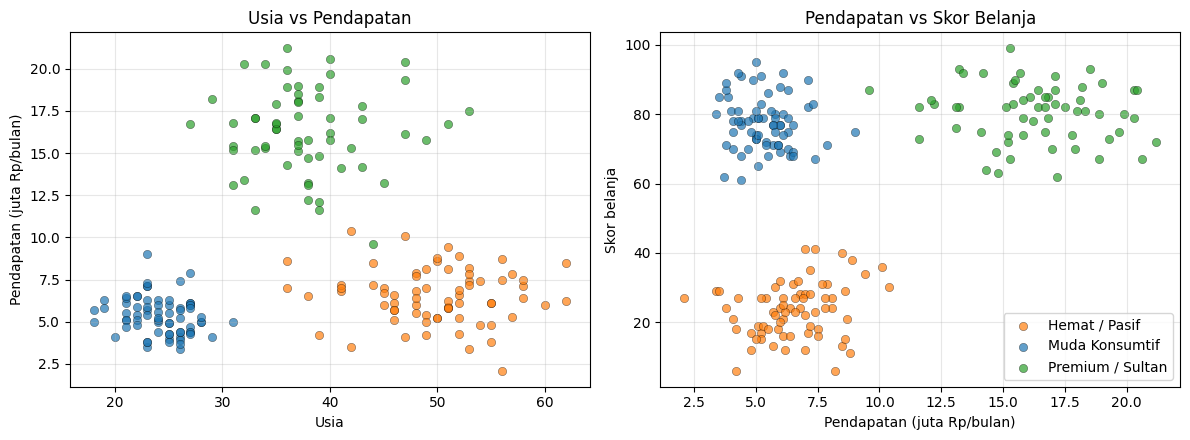

In [ ]:
# Visualisasi hasil clustering (usia vs pendapatan, usia vs skor belanja)
warna = {'Muda Konsumtif': 'tab:blue', 'Premium / Sultan': 'tab:green', 'Hemat / Pasif': 'tab:orange'}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for s, g in df.groupby('segmen'):
    ax[0].scatter(g['usia'], g['pendapatan'] / 1e6, c=warna[s], label=s, alpha=.7, edgecolor='k', lw=.3)
    ax[1].scatter(g['pendapatan'] / 1e6, g['skor_belanja'], c=warna[s], label=s, alpha=.7, edgecolor='k', lw=.3)
ax[0].set_xlabel('Usia'); ax[0].set_ylabel('Pendapatan (juta Rp/bulan)'); ax[0].set_title('Usia vs Pendapatan')
ax[1].set_xlabel('Pendapatan (juta Rp/bulan)'); ax[1].set_ylabel('Skor belanja'); ax[1].set_title('Pendapatan vs Skor Belanja')
ax[1].legend(); [a.grid(alpha=.3) for a in ax]
plt.tight_layout(); plt.show()

## D. Latihan Mandiri

### Latihan 1 — K=5 vs K=3 (silhouette)

In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
lab5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, lab5)
print(f'Silhouette K=3: {sil_k3:.3f}')
print(f'Silhouette K=5: {sil_k5:.3f}')
print('Ukuran cluster K=5:', np.bincount(lab5))

Silhouette K=3: 0.702
Silhouette K=5: 0.452
Ukuran cluster K=5: [36 41 70 29 24]


**Kesimpulan:** silhouette K=5 (≈0,45) lebih rendah daripada K=3 (≈0,70). Data sebenarnya hanya memiliki 3 kelompok alami, sehingga K=5 memecah kelompok yang utuh menjadi potongan-potongan yang saling berdekatan (separasi antar-cluster mengecil). **K=3 lebih baik**, konsisten dengan hasil Elbow.

### Latihan 2 — K-Means tanpa scaling (K=3)

In [ ]:
X_raw = df[['usia', 'pendapatan', 'skor_belanja']].values
lab_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_raw)
sil_raw = silhouette_score(X_raw, lab_raw)
print(f'Silhouette dengan scaling   : {sil_k3:.3f}')
print(f'Silhouette tanpa scaling    : {sil_raw:.3f}')
print('Ukuran cluster tanpa scaling:', np.bincount(lab_raw))

# Seberapa sesuai dengan segmen "sebenarnya" (hasil dengan scaling)?
print('\nTabulasi silang (baris = segmen scaled, kolom = cluster tanpa scaling):')
display(pd.crosstab(df['segmen'], lab_raw))

print('\nProfil cluster tanpa scaling:')
display(df.assign(c_raw=lab_raw).groupby('c_raw')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1))

Silhouette dengan scaling   : 0.702
Silhouette tanpa scaling    : 0.606
Ukuran cluster tanpa scaling: [102  55  43]

Tabulasi silang (baris = segmen scaled, kolom = cluster tanpa scaling):


col_0,0,1,2
segmen,,,
Hemat / Pasif,38,0,32
Muda Konsumtif,64,0,6
Premium / Sultan,0,55,5



Profil cluster tanpa scaling:


,usia,pendapatan,skor_belanja
c_raw,,,
0,33.9,5228431.4,56.7
1,37.8,16740000.0,80.2
2,44.6,8279069.8,39.4


**Kesimpulan:** tanpa scaling, jarak hampir sepenuhnya ditentukan oleh `pendapatan` (satuan jutaan rupiah) sedangkan `usia` dan `skor_belanja` (satuan puluhan) nyaris tidak berpengaruh. Tabulasi silang menunjukkan cluster yang terbentuk **mencampur** segmen Muda Konsumtif dan Hemat/Pasif karena keduanya berpendapatan serupa, padahal perilaku belanjanya sangat berbeda. Nilai silhouette turun (≈0,61 vs ≈0,70), dan—yang lebih penting—cluster menjadi kurang bermakna secara bisnis. Karena silhouette dihitung pada ruang fitur yang sama dengan yang dipakai clustering, nilainya perlu dibaca bersama tabulasi/profil cluster, bukan sebagai satu-satunya ukuran. **Scaling wajib** untuk algoritma berbasis jarak.

### Latihan 3 — Scatter plot usia (x) vs skor_belanja (y)

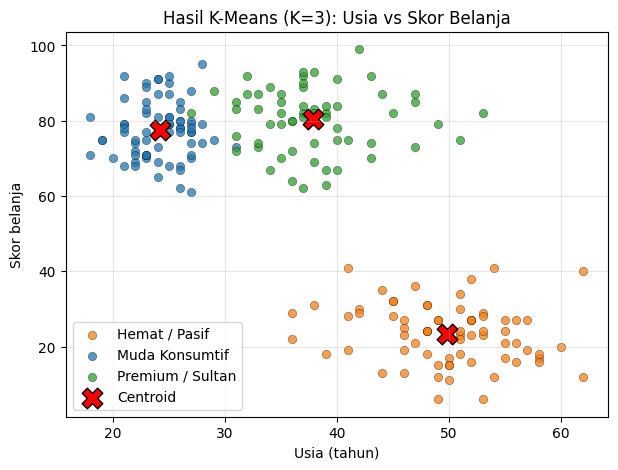

In [ ]:
plt.figure(figsize=(7, 5))
for s, g in df.groupby('segmen'):
    plt.scatter(g['usia'], g['skor_belanja'], c=warna[s], label=s, alpha=.75, edgecolor='k', lw=.3)

# centroid dikembalikan ke skala asli
scaler = StandardScaler().fit(df[['usia', 'pendapatan', 'skor_belanja']])
cent = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(cent[:, 0], cent[:, 2], c='red', marker='X', s=220, edgecolor='k', label='Centroid')
plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja')
plt.title('Hasil K-Means (K=3): Usia vs Skor Belanja')
plt.legend(); plt.grid(alpha=.3); plt.show()

**Pengamatan:** pada bidang usia–skor belanja, segmen Hemat/Pasif terpisah jelas (usia lebih tua, skor rendah), sedangkan Muda Konsumtif dan Premium sama-sama berskor tinggi dan lebih sulit dibedakan hanya dari dua fitur ini—pembeda utamanya adalah `pendapatan`, sehingga ketiga fitur perlu dipakai bersama.

## E. Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**
K-Means tidak memakai label; ia hanya memanfaatkan kemiripan (jarak) antar titik. Algoritma menempatkan K centroid awal secara acak, lalu mengulang dua langkah: (a) *assignment* — tiap titik dimasukkan ke centroid terdekat; (b) *update* — centroid dihitung ulang sebagai rata-rata anggotanya. Proses berhenti ketika centroid tidak lagi bergeser (konvergen), sehingga titik-titik yang berdekatan terkumpul dalam satu cluster dan inertia (jumlah kuadrat jarak ke centroid) diminimalkan. Makna cluster baru muncul setelah kita menafsirkan profilnya.

**2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**
Karena data memang dibangkitkan dari tiga kelompok alami. Dari K=1 ke K=3, setiap penambahan cluster memisahkan kelompok yang benar-benar berbeda sehingga inertia turun drastis. Setelah K=3, setiap kelompok sudah kompak; cluster tambahan hanya membelah kelompok yang utuh dan mengurangi inertia sedikit saja, sehingga kurva melandai membentuk "siku". Silhouette tertinggi di K=3 menguatkan pilihan ini.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**
K-Means memakai jarak Euclidean, sehingga fitur berskala besar mendominasi. Di sini `pendapatan` (jutaan) membuat `usia` dan `skor_belanja` nyaris tak berpengaruh. Bila scaling dilewatkan, cluster pada dasarnya hanya mengelompokkan berdasarkan pendapatan, segmen dengan perilaku berbeda tercampur (lihat Latihan 2), dan interpretasi bisnisnya menyesatkan. Scaling menyetarakan kontribusi tiap fitur.

## Kesimpulan
- Data diskalakan dengan `StandardScaler` sebelum clustering.
- Elbow dan silhouette sama-sama mendukung **K = 3**; silhouette K=3 lebih tinggi daripada K=5.
- Tiga segmen: **Muda Konsumtif**, **Premium / Sultan**, dan **Hemat / Pasif**, masing-masing dengan strategi pemasaran berbeda.
- Tanpa scaling, cluster didominasi pendapatan dan mencampur segmen yang berperilaku berbeda.